# CAS-Match Results Analysis Notebook

**Purpose:** produce the report-ready tables, plots, confusion matrices, calibration summaries and training-history figures from the experiment outputs already saved on disk.

**This notebook does not train models or modify experiment outputs.** It reads `test_metrics.json`, `history.csv`, `threshold_calibration.csv` and `pseudo_label_epoch_diagnostics.csv` from completed run folders, then writes a separate `report_results` folder.

It supports the original seed-42 exploratory runs and additional seed folders (for example seeds 43 and 44) when those folders exist. Missing experiments are reported as missing, never fabricated.


## 1. Set the project location

The default path matches the project folder used in the experiment notebooks. If your project is stored elsewhere, edit `PROJECT_ROOT` below.

Expected input folder:

`PROJECT_ROOT/data/results/cas_match_v1/`

Expected run-folder names resemble:

`cric_5pct_cas_match_seed42/`


In [1]:
from pathlib import Path
import json, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# EDIT THIS ONLY IF YOUR PROJECT FOLDER IS IN A DIFFERENT LOCATION.
PROJECT_ROOT = Path.home() / "Documents" / "cervical-semi-sl"

RESULTS_DIR = PROJECT_ROOT / "data" / "results" / "cas_match_v1"
REPORT_DIR = RESULTS_DIR / "report_results"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

METHOD_ORDER = ["fixmatch", "lower_only", "agreement_only", "stability_only", "cas_match"]
METHOD_LABELS = {
    "fixmatch": "FixMatch",
    "lower_only": "Lower-only",
    "agreement_only": "Agreement-only",
    "stability_only": "Stability-only",
    "cas_match": "CAS-Match",
}
DATASET_ORDER = ["cric", "riva"]
METRICS = [
    "macro_f1", "auroc", "accuracy", "balanced_accuracy",
    "abnormal_recall", "precision_abnormal", "specificity_normal",
    "normal_f1", "abnormal_f1"
]

if not RESULTS_DIR.exists():
    raise FileNotFoundError(
        f"Could not find: {RESULTS_DIR}\n"
        "Set PROJECT_ROOT to the folder containing data/results/cas_match_v1."
    )

print("Reading experiment outputs from:", RESULTS_DIR)
print("Writing report assets to:", REPORT_DIR)


Reading experiment outputs from: C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1
Writing report assets to: C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\report_results


## 2. Discover completed runs and load the saved metrics

A run is included only when its `test_metrics.json` exists and can be parsed. `DONE.json` alone is not treated as a result. The seed is extracted from the run-folder name.


In [2]:
records = []
run_dirs = sorted(p for p in RESULTS_DIR.iterdir() if p.is_dir() and re.match(
    r"^(cric|riva)_\d+pct_(fixmatch|lower_only|agreement_only|stability_only|cas_match)_seed\d+$",
    p.name
))

for run_dir in run_dirs:
    metrics_path = run_dir / "test_metrics.json"
    if not metrics_path.exists():
        continue
    try:
        payload = json.loads(metrics_path.read_text(encoding="utf-8"))
        match = re.search(r"_seed(\d+)$", run_dir.name)
        seed = int(match.group(1)) if match else np.nan
        row = {
            "run_id": payload.get("run_id", run_dir.name),
            "dataset": str(payload.get("dataset", run_dir.name.split("_")[0])).lower(),
            "label_fraction": float(payload.get("label_fraction", np.nan)),
            "method": str(payload.get("method", "")).lower(),
            "seed": seed,
            "best_epoch": payload.get("best_epoch", np.nan),
            "best_val_macro_f1": payload.get("best_val_macro_f1", np.nan),
            "tau_low_normal": payload.get("tau_low_normal", np.nan),
            "tau_low_abnormal": payload.get("tau_low_abnormal", np.nan),
            "config_hash": payload.get("config_hash", ""),
            "run_dir": str(run_dir),
        }
        row.update(payload.get("test_metrics", {}))
        records.append(row)
    except Exception as exc:
        warnings.warn(f"Skipping unreadable result {metrics_path}: {exc}")

results = pd.DataFrame(records)
if results.empty:
    raise RuntimeError(
        "No test_metrics.json files were found. Check that the experiment runs have completed "
        "and that RESULTS_DIR points to cas_match_v1."
    )

results["label_percent"] = (results["label_fraction"] * 100).round().astype(int)
results["method_label"] = results["method"].map(METHOD_LABELS).fillna(results["method"])
results = results.sort_values(["dataset", "label_fraction", "method", "seed"]).reset_index(drop=True)

print(f"Loaded {len(results)} completed run(s).")
display(results[["run_id", "dataset", "label_percent", "method_label", "seed",
                 "best_epoch", "macro_f1", "auroc"]])
results.to_csv(REPORT_DIR / "all_completed_run_metrics.csv", index=False)


Loaded 12 completed run(s).


,run_id,dataset,label_percent,method_label,seed,best_epoch,macro_f1,auroc
0,cric_5pct_agreement_only_seed42,cric,5,Agreement-only,42,19,0.848182,0.938728
1,cric_5pct_cas_match_seed42,cric,5,CAS-Match,42,8,0.846915,0.941513
2,cric_5pct_fixmatch_seed42,cric,5,FixMatch,42,7,0.848300,0.942340
3,cric_5pct_lower_only_seed42,cric,5,Lower-only,42,4,0.839857,0.928174
4,cric_5pct_stability_only_seed42,cric,5,Stability-only,42,3,0.827557,0.919568
5,cric_10pct_agreement_only_seed42,cric,10,Agreement-only,42,2,0.851439,0.941882
6,cric_10pct_cas_match_seed42,cric,10,CAS-Match,42,12,0.859336,0.950800
7,cric_10pct_fixmatch_seed42,cric,10,FixMatch,42,3,0.853600,0.947860
8,cric_10pct_lower_only_seed42,cric,10,Lower-only,42,4,0.861379,0.947803
9,cric_10pct_stability_only_seed42,cric,10,Stability-only,42,7,0.873787,0.951133


## 3. Completion audit

This table makes incomplete parts visible. It is intentionally not an experiment launcher.


In [3]:
audit_rows = []
for ds in DATASET_ORDER:
    for pct in [5, 10]:
        for method in METHOD_ORDER:
            subset = results[
                (results.dataset == ds) &
                (results.label_percent == pct) &
                (results.method == method)
            ]
            seeds = sorted(subset.seed.dropna().astype(int).unique().tolist())
            audit_rows.append({
                "dataset": ds.upper(),
                "label_budget": f"{pct}%",
                "method": METHOD_LABELS[method],
                "completed_runs": len(subset),
                "seeds_found": ", ".join(map(str, seeds)) if seeds else "None",
                "status": "Available" if len(subset) else "Not available"
            })
completion_audit = pd.DataFrame(audit_rows)
display(completion_audit)
completion_audit.to_csv(REPORT_DIR / "completion_audit.csv", index=False)


,dataset,label_budget,method,completed_runs,seeds_found,status
0,CRIC,5%,FixMatch,1,42,Available
1,CRIC,5%,Lower-only,1,42,Available
2,CRIC,5%,Agreement-only,1,42,Available
3,CRIC,5%,Stability-only,1,42,Available
4,CRIC,5%,CAS-Match,1,42,Available
5,CRIC,10%,FixMatch,1,42,Available
6,CRIC,10%,Lower-only,1,42,Available
7,CRIC,10%,Agreement-only,1,42,Available
8,CRIC,10%,Stability-only,1,42,Available
9,CRIC,10%,CAS-Match,1,42,Available


## 4. Per-run result table

This is the exact run-level table. Keep it in the appendix or supplementary results so every displayed aggregate can be traced back to a run.


In [4]:
run_cols = [
    "dataset", "label_percent", "method_label", "seed", "best_epoch",
    "best_val_macro_f1", "macro_f1", "auroc", "accuracy", "balanced_accuracy",
    "precision_abnormal", "abnormal_recall", "specificity_normal",
    "normal_f1", "abnormal_f1", "tn", "fp", "fn", "tp",
    "tau_low_normal", "tau_low_abnormal", "config_hash", "run_id"
]
run_table = results[[c for c in run_cols if c in results.columns]].copy()
display(run_table)
run_table.to_csv(REPORT_DIR / "per_run_results.csv", index=False)


,dataset,label_percent,method_label,seed,best_epoch,best_val_macro_f1,macro_f1,auroc,accuracy,balanced_accuracy,...,normal_f1,abnormal_f1,tn,fp,fn,tp,tau_low_normal,tau_low_abnormal,config_hash,run_id
0,cric,5,Agreement-only,42,19,0.844723,0.848182,0.938728,0.870828,0.849294,...,0.906817,0.789548,1450,153,145,559,0.80,0.80,e213e0fc343fe38f,cric_5pct_agreement_only_seed42
1,cric,5,CAS-Match,42,8,0.849024,0.846915,0.941513,0.875163,0.834489,...,0.912674,0.781155,1505,98,190,514,0.80,0.80,e213e0fc343fe38f,cric_5pct_cas_match_seed42
2,cric,5,FixMatch,42,7,0.842080,0.848300,0.942340,0.874296,0.840637,...,0.911097,0.785503,1486,117,173,531,0.95,0.95,e213e0fc343fe38f,cric_5pct_fixmatch_seed42
3,cric,5,Lower-only,42,4,0.841725,0.839857,0.928174,0.858257,0.856181,...,0.894140,0.785574,1381,222,105,599,0.80,0.80,e213e0fc343fe38f,cric_5pct_lower_only_seed42
4,cric,5,Stability-only,42,3,0.830251,0.827557,0.919568,0.847421,0.843205,...,0.886084,0.769029,1369,234,118,586,0.95,0.95,e213e0fc343fe38f,cric_5pct_stability_only_seed42
5,cric,10,Agreement-only,42,2,0.867102,0.851439,0.941882,0.876896,0.843703,...,0.912937,0.789941,1489,114,170,534,0.95,0.95,e213e0fc343fe38f,cric_10pct_agreement_only_seed42
6,cric,10,CAS-Match,42,12,0.871465,0.859336,0.950800,0.877763,0.868624,...,0.910248,0.808424,1430,173,109,595,0.80,0.80,e213e0fc343fe38f,cric_10pct_cas_match_seed42
7,cric,10,FixMatch,42,3,0.868446,0.853600,0.947860,0.876029,0.853037,...,0.910903,0.796296,1462,141,145,559,0.95,0.95,e213e0fc343fe38f,cric_10pct_fixmatch_seed42
8,cric,10,Lower-only,42,4,0.866338,0.861379,0.947803,0.879064,0.872348,...,0.910891,0.811868,1426,177,102,602,0.80,0.80,e213e0fc343fe38f,cric_10pct_lower_only_seed42
9,cric,10,Stability-only,42,7,0.864993,0.873787,0.951133,0.892068,0.876926,...,0.921821,0.825752,1468,135,114,590,0.80,0.60,e213e0fc343fe38f,cric_10pct_stability_only_seed42


## 5. Aggregate results across seeds

For each dataset, label budget and method, calculate mean and sample standard deviation across the seeds that actually exist. With one seed, standard deviation is left undefined. Do not describe a one-seed result as a three-seed mean.


In [5]:
group_cols = ["dataset", "label_percent", "method", "method_label"]
available_metrics = [m for m in METRICS if m in results.columns]
agg = results.groupby(group_cols, dropna=False)[available_metrics].agg(["mean", "std", "count"])
agg.columns = [f"{metric}_{stat}" for metric, stat in agg.columns]
aggregate_table = agg.reset_index().sort_values(["dataset", "label_percent", "method"])
display(aggregate_table)
aggregate_table.to_csv(REPORT_DIR / "mean_std_by_dataset_budget_method.csv", index=False)

# Compact report table: mean ± SD, while preserving n.
compact_rows = []
for _, r in aggregate_table.iterrows():
    row = {
        "Dataset": str(r["dataset"]).upper(),
        "Label budget": f'{int(r["label_percent"])}%',
        "Method": r["method_label"],
        "n seeds": int(r["macro_f1_count"]) if "macro_f1_count" in r else 0,
    }
    for metric in available_metrics:
        mean = r.get(f"{metric}_mean", np.nan)
        sd = r.get(f"{metric}_std", np.nan)
        row[metric] = f"{mean:.4f} ± {sd:.4f}" if pd.notna(sd) else (f"{mean:.4f}" if pd.notna(mean) else "NA")
    compact_rows.append(row)
compact_table = pd.DataFrame(compact_rows)
display(compact_table)
compact_table.to_csv(REPORT_DIR / "report_compact_mean_sd_table.csv", index=False)


,dataset,label_percent,method,method_label,macro_f1_mean,macro_f1_std,macro_f1_count,auroc_mean,auroc_std,auroc_count,...,precision_abnormal_count,specificity_normal_mean,specificity_normal_std,specificity_normal_count,normal_f1_mean,normal_f1_std,normal_f1_count,abnormal_f1_mean,abnormal_f1_std,abnormal_f1_count
0,cric,5,agreement_only,Agreement-only,0.848182,NaN,1,0.938728,NaN,1,...,1,0.904554,NaN,1,0.906817,NaN,1,0.789548,NaN,1
1,cric,5,cas_match,CAS-Match,0.846915,NaN,1,0.941513,NaN,1,...,1,0.938865,NaN,1,0.912674,NaN,1,0.781155,NaN,1
2,cric,5,fixmatch,FixMatch,0.848300,NaN,1,0.942340,NaN,1,...,1,0.927012,NaN,1,0.911097,NaN,1,0.785503,NaN,1
3,cric,5,lower_only,Lower-only,0.839857,NaN,1,0.928174,NaN,1,...,1,0.861510,NaN,1,0.894140,NaN,1,0.785574,NaN,1
4,cric,5,stability_only,Stability-only,0.827557,NaN,1,0.919568,NaN,1,...,1,0.854024,NaN,1,0.886084,NaN,1,0.769029,NaN,1
5,cric,10,agreement_only,Agreement-only,0.851439,NaN,1,0.941882,NaN,1,...,1,0.928883,NaN,1,0.912937,NaN,1,0.789941,NaN,1
6,cric,10,cas_match,CAS-Match,0.859336,NaN,1,0.950800,NaN,1,...,1,0.892077,NaN,1,0.910248,NaN,1,0.808424,NaN,1
7,cric,10,fixmatch,FixMatch,0.853600,NaN,1,0.947860,NaN,1,...,1,0.912040,NaN,1,0.910903,NaN,1,0.796296,NaN,1
8,cric,10,lower_only,Lower-only,0.861379,NaN,1,0.947803,NaN,1,...,1,0.889582,NaN,1,0.910891,NaN,1,0.811868,NaN,1
9,cric,10,stability_only,Stability-only,0.873787,NaN,1,0.951133,NaN,1,...,1,0.915783,NaN,1,0.921821,NaN,1,0.825752,NaN,1


,Dataset,Label budget,Method,n seeds,macro_f1,auroc,accuracy,balanced_accuracy,abnormal_recall,precision_abnormal,specificity_normal,normal_f1,abnormal_f1
0,CRIC,5%,Agreement-only,1,0.8482,0.9387,0.8708,0.8493,0.7940,0.7851,0.9046,0.9068,0.7895
1,CRIC,5%,CAS-Match,1,0.8469,0.9415,0.8752,0.8345,0.7301,0.8399,0.9389,0.9127,0.7812
2,CRIC,5%,FixMatch,1,0.8483,0.9423,0.8743,0.8406,0.7543,0.8194,0.9270,0.9111,0.7855
3,CRIC,5%,Lower-only,1,0.8399,0.9282,0.8583,0.8562,0.8509,0.7296,0.8615,0.8941,0.7856
4,CRIC,5%,Stability-only,1,0.8276,0.9196,0.8474,0.8432,0.8324,0.7146,0.8540,0.8861,0.7690
5,CRIC,10%,Agreement-only,1,0.8514,0.9419,0.8769,0.8437,0.7585,0.8241,0.9289,0.9129,0.7899
6,CRIC,10%,CAS-Match,1,0.8593,0.9508,0.8778,0.8686,0.8452,0.7747,0.8921,0.9102,0.8084
7,CRIC,10%,FixMatch,1,0.8536,0.9479,0.8760,0.8530,0.7940,0.7986,0.9120,0.9109,0.7963
8,CRIC,10%,Lower-only,1,0.8614,0.9478,0.8791,0.8723,0.8551,0.7728,0.8896,0.9109,0.8119
9,CRIC,10%,Stability-only,1,0.8738,0.9511,0.8921,0.8769,0.8381,0.8138,0.9158,0.9218,0.8258


## 6. Main comparison plots

The plots use only observed runs. When multiple seeds exist, bars show the mean and error bars show one sample standard deviation. With one seed, no error bar is drawn.


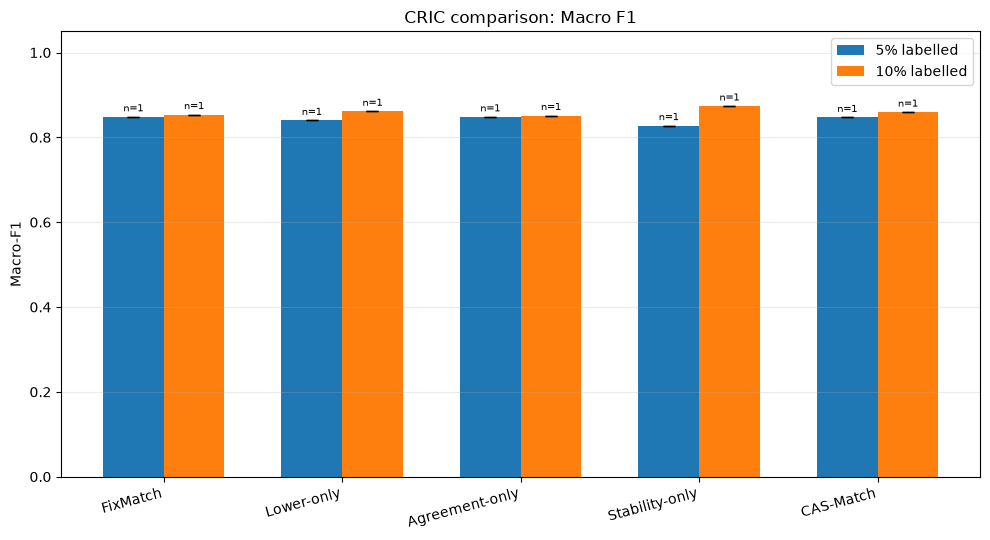

Saved: C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\report_results\cric_macro_f1_comparison.png


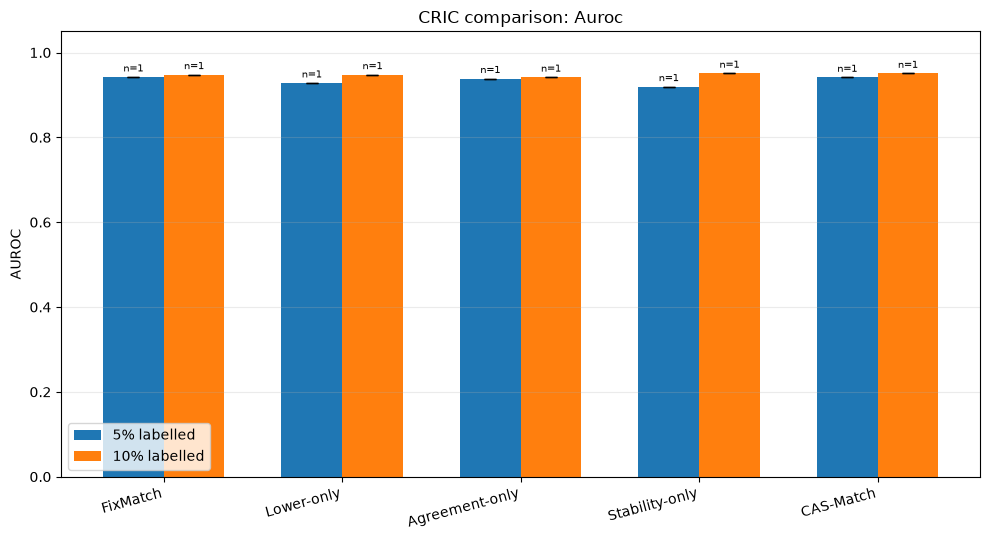

Saved: C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\report_results\cric_auroc_comparison.png


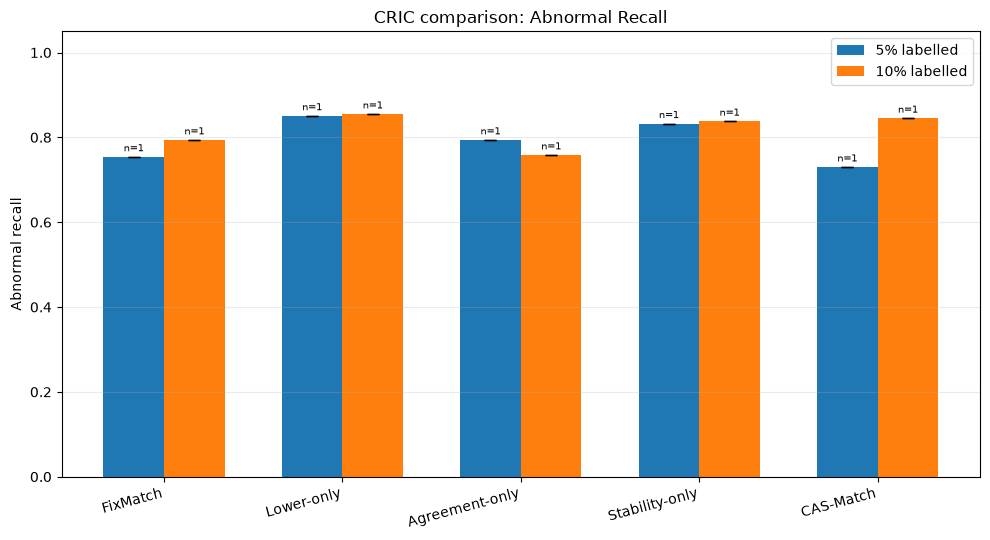

Saved: C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\report_results\cric_abnormal_recall_comparison.png


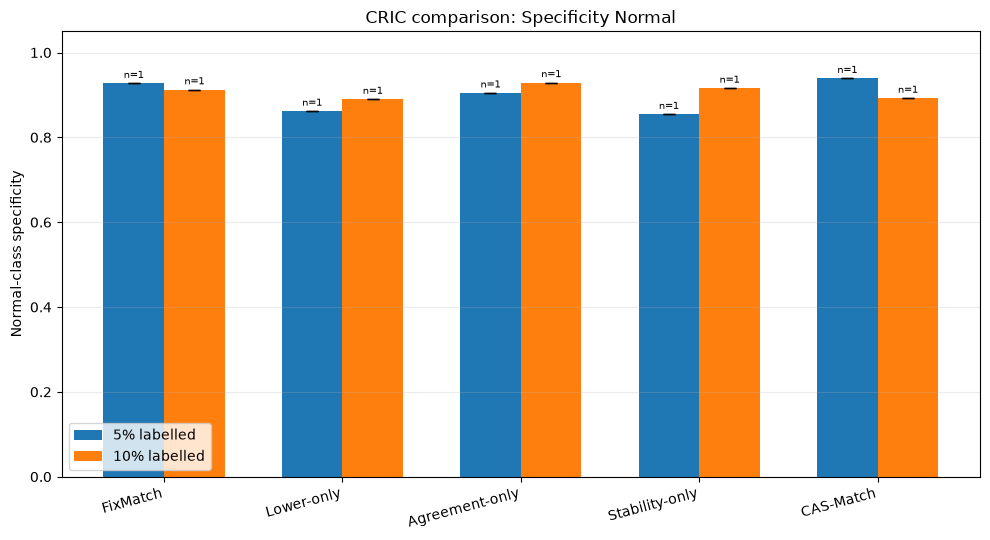

Saved: C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\report_results\cric_specificity_comparison.png


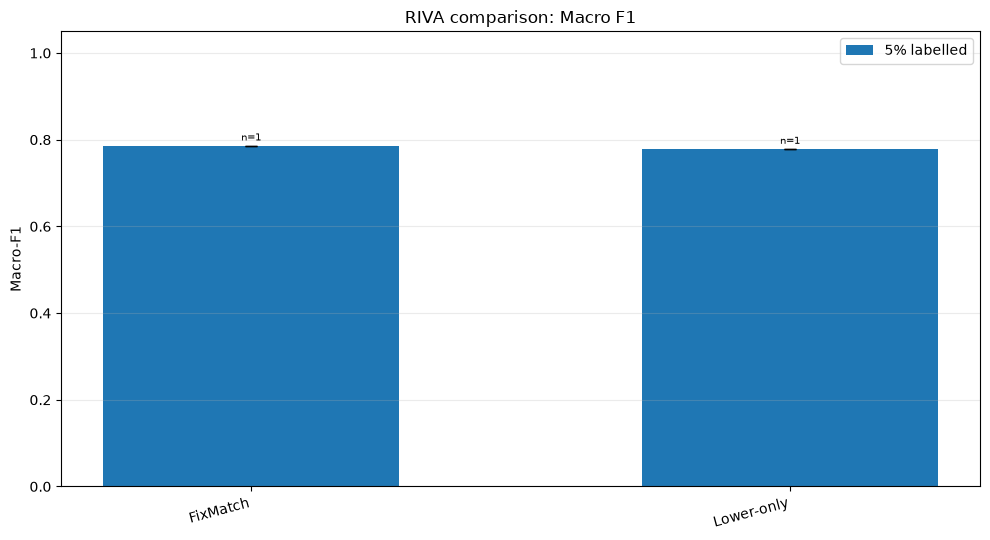

Saved: C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\report_results\riva_macro_f1_comparison.png


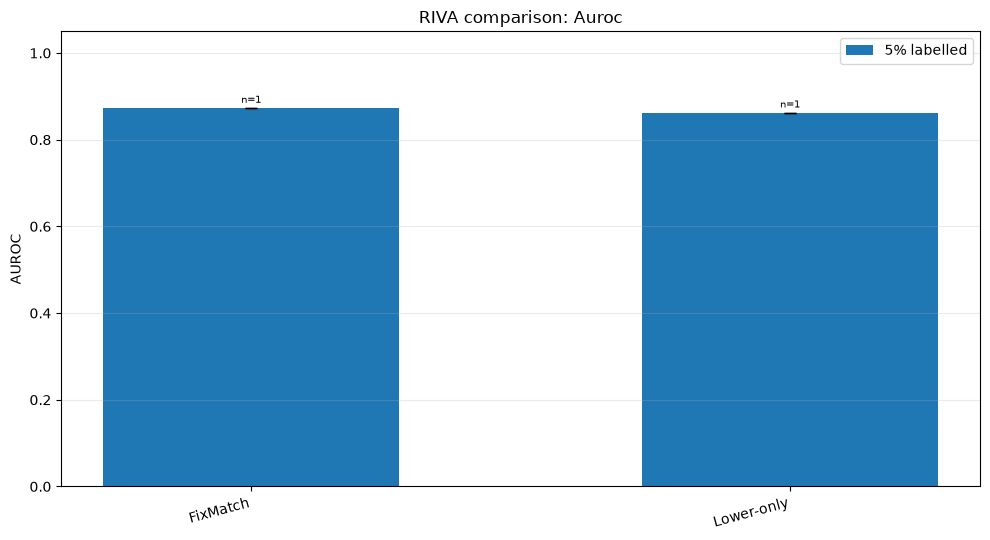

Saved: C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\report_results\riva_auroc_comparison.png


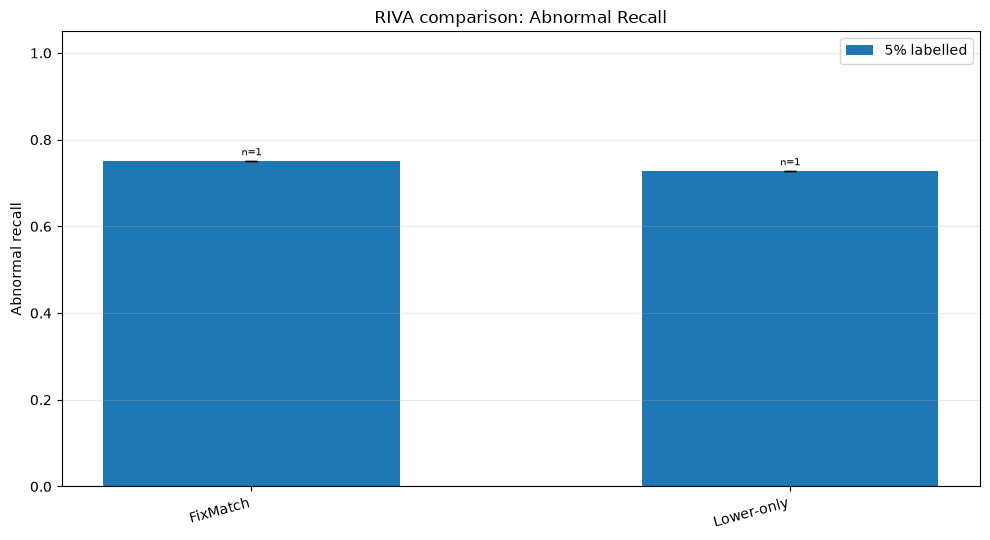

Saved: C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\report_results\riva_abnormal_recall_comparison.png


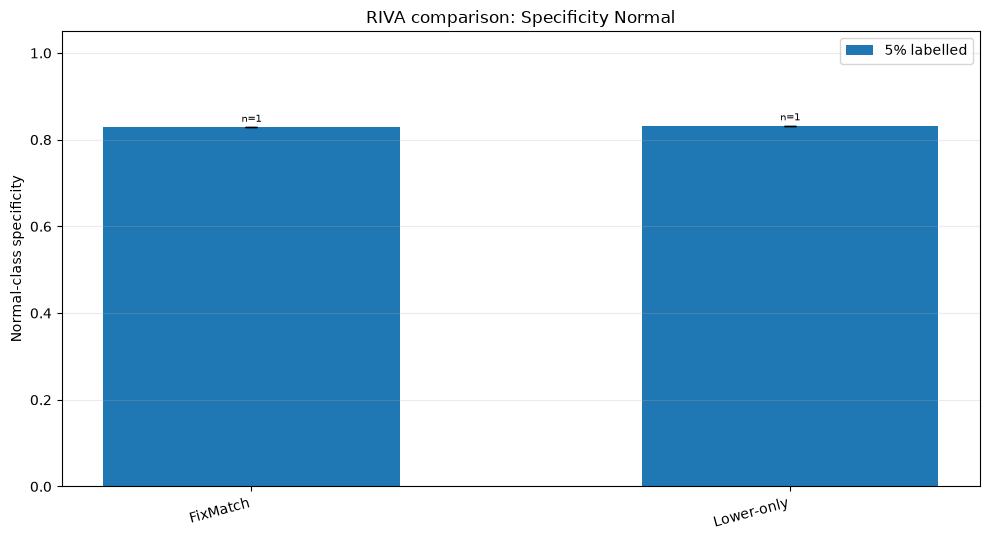

Saved: C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\report_results\riva_specificity_comparison.png


In [6]:
def plot_metric(metric, dataset, filename, ylabel=None):
    sub = aggregate_table[aggregate_table.dataset == dataset].copy()
    if sub.empty or f"{metric}_mean" not in sub.columns:
        print(f"No {metric} results for {dataset.upper()}; skipping.")
        return
    budgets = sorted(sub.label_percent.unique())
    methods = [m for m in METHOD_ORDER if m in sub.method.unique()]
    x = np.arange(len(methods))
    width = 0.34 if len(budgets) == 2 else 0.55
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for j, pct in enumerate(budgets):
        ss = sub[sub.label_percent == pct].set_index("method")
        means = [ss.loc[m, f"{metric}_mean"] if m in ss.index else np.nan for m in methods]
        sds = [ss.loc[m, f"{metric}_std"] if m in ss.index else np.nan for m in methods]
        counts = [ss.loc[m, f"{metric}_count"] if m in ss.index else 0 for m in methods]
        errs = [sd if count > 1 and pd.notna(sd) else 0 for sd, count in zip(sds, counts)]
        offset = (j - (len(budgets)-1)/2) * width
        bars = ax.bar(x + offset, means, width, yerr=errs, capsize=4, label=f"{pct}% labelled")
        for bar, count in zip(bars, counts):
            if bar.get_height() == bar.get_height():
                ax.annotate(f"n={int(count)}", (bar.get_x()+bar.get_width()/2, bar.get_height()),
                            xytext=(0, 4), textcoords="offset points", ha="center", fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels([METHOD_LABELS[m] for m in methods], rotation=15, ha="right")
    ax.set_ylabel(ylabel or metric.replace("_", " ").title())
    ax.set_title(f"{dataset.upper()} comparison: {metric.replace('_', ' ').title()}")
    ax.set_ylim(0, 1.05)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
    fig.tight_layout()
    path = REPORT_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", path)

for ds in ["cric", "riva"]:
    plot_metric("macro_f1", ds, f"{ds}_macro_f1_comparison.png", "Macro-F1")
    plot_metric("auroc", ds, f"{ds}_auroc_comparison.png", "AUROC")
    plot_metric("abnormal_recall", ds, f"{ds}_abnormal_recall_comparison.png", "Abnormal recall")
    plot_metric("specificity_normal", ds, f"{ds}_specificity_comparison.png", "Normal-class specificity")


## 7. CAS-Match versus FixMatch: paired seed-level differences

For seeds where both methods exist under the same dataset and label budget, calculate CAS-Match minus FixMatch. This is a descriptive paired comparison, not a significance test.


In [7]:
paired_rows = []
for (ds, pct), block in results.groupby(["dataset", "label_percent"]):
    cas = block[block.method == "cas_match"].set_index("seed")
    fix = block[block.method == "fixmatch"].set_index("seed")
    common = sorted(set(cas.index).intersection(fix.index))
    for seed in common:
        row = {"dataset": ds.upper(), "label_budget": f"{pct}%", "seed": int(seed)}
        for metric in ["macro_f1", "auroc", "abnormal_recall", "specificity_normal"]:
            if metric in block.columns:
                row[f"cas_minus_fixmatch_{metric}"] = cas.loc[seed, metric] - fix.loc[seed, metric]
        paired_rows.append(row)
paired_deltas = pd.DataFrame(paired_rows)
display(paired_deltas if not paired_deltas.empty else pd.DataFrame({"Note":["No matched CAS-Match/FixMatch seed pairs found."]}))
paired_deltas.to_csv(REPORT_DIR / "paired_seed_deltas_cas_vs_fixmatch.csv", index=False)

if not paired_deltas.empty:
    delta_cols = [c for c in paired_deltas.columns if c.startswith("cas_minus_fixmatch_")]
    paired_summary = paired_deltas.groupby(["dataset", "label_budget"])[delta_cols].agg(["mean", "std", "count"])
    paired_summary.to_csv(REPORT_DIR / "paired_delta_summary.csv")
    display(paired_summary)


,dataset,label_budget,seed,cas_minus_fixmatch_macro_f1,cas_minus_fixmatch_auroc,cas_minus_fixmatch_abnormal_recall,cas_minus_fixmatch_specificity_normal
0,CRIC,5%,42,-0.001386,-0.000827,-0.024148,0.011853
1,CRIC,10%,42,0.005736,0.002940,0.051136,-0.019963


cas_minus_fixmatch_macro_f1            \
                                            mean std count   
dataset label_budget                                         
CRIC    10%                             0.005736 NaN     1   
        5%                             -0.001386 NaN     1   

                     cas_minus_fixmatch_auroc            \
                                         mean std count   
dataset label_budget                                      
CRIC    10%                          0.002940 NaN     1   
        5%                          -0.000827 NaN     1   

                     cas_minus_fixmatch_abnormal_recall            \
                                                   mean std count   
dataset label_budget                                                
CRIC    10%                                    0.051136 NaN     1   
        5%                                    -0.024148 NaN     1   

                     cas_minus_fixmatch_specificity_normal            
                                                      mean std count  
dataset label_budget                                                  
CRIC    10%                                      -0.019963 NaN     1  
        5%                                        0.011853 NaN     1

## 8. Confusion matrices

The experiment evaluator saved TN, FP, FN and TP in `test_metrics.json`. This notebook reconstructs the corresponding 2×2 matrices without needing model checkpoints or image inference.


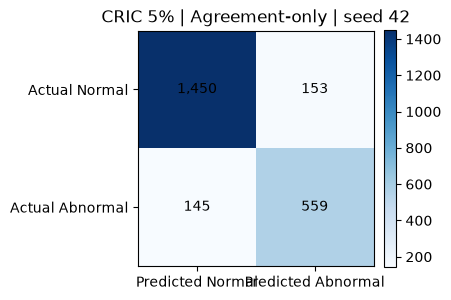

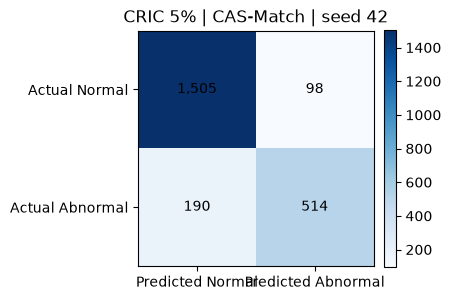

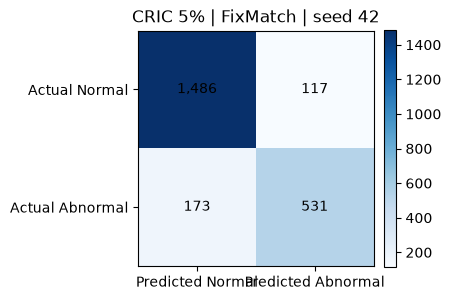

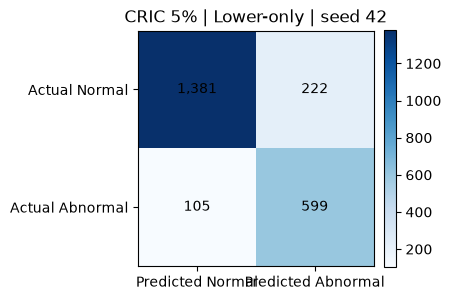

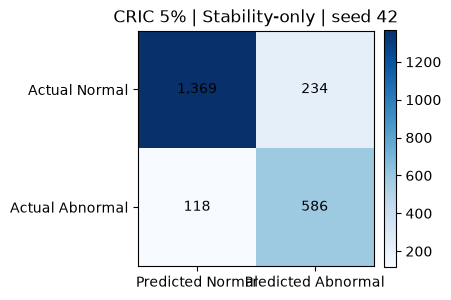

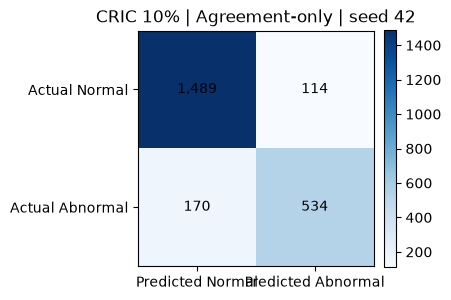

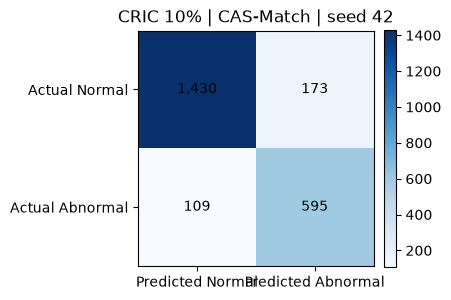

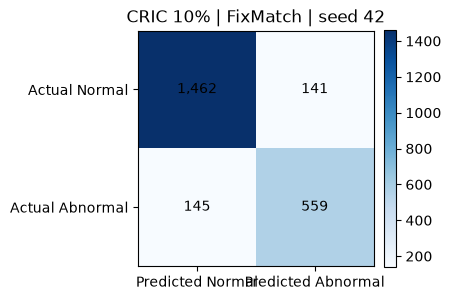

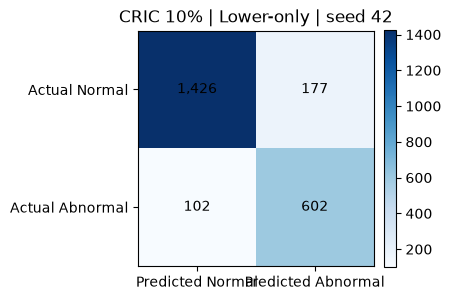

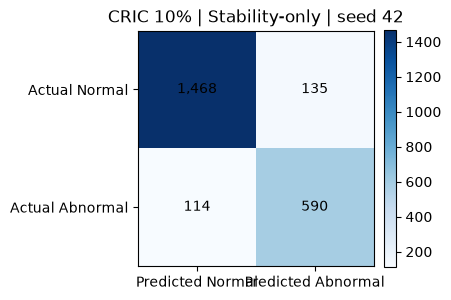

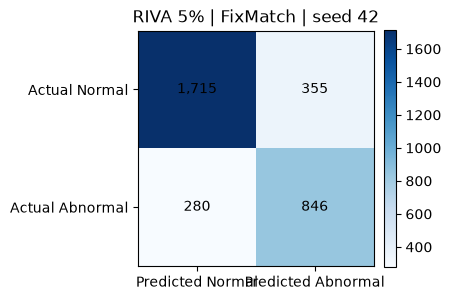

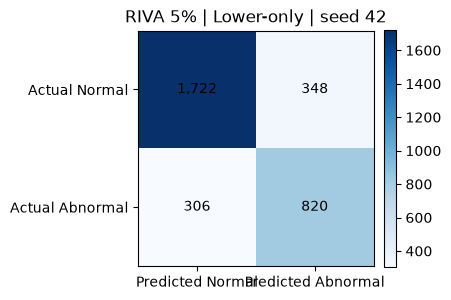

,dataset,label_budget,method,seed,TN,FP,FN,TP
0,CRIC,5%,Agreement-only,42,1450,153,145,559
1,CRIC,5%,CAS-Match,42,1505,98,190,514
2,CRIC,5%,FixMatch,42,1486,117,173,531
3,CRIC,5%,Lower-only,42,1381,222,105,599
4,CRIC,5%,Stability-only,42,1369,234,118,586
5,CRIC,10%,Agreement-only,42,1489,114,170,534
6,CRIC,10%,CAS-Match,42,1430,173,109,595
7,CRIC,10%,FixMatch,42,1462,141,145,559
8,CRIC,10%,Lower-only,42,1426,177,102,602
9,CRIC,10%,Stability-only,42,1468,135,114,590


In [8]:
cm_rows = []
for _, r in results.iterrows():
    keys = ["tn", "fp", "fn", "tp"]
    if all(k in r.index and pd.notna(r[k]) for k in keys):
        cm = np.array([[int(r.tn), int(r.fp)], [int(r.fn), int(r.tp)]])
        cm_rows.append({
            "dataset": r.dataset.upper(), "label_budget": f"{int(r.label_percent)}%",
            "method": r.method_label, "seed": int(r.seed),
            "TN": int(r.tn), "FP": int(r.fp), "FN": int(r.fn), "TP": int(r.tp),
            "confusion_matrix": cm.tolist()
        })
        fig, ax = plt.subplots(figsize=(4.5, 4))
        im = ax.imshow(cm, cmap="Blues")
        ax.set_xticks([0,1], ["Predicted Normal", "Predicted Abnormal"])
        ax.set_yticks([0,1], ["Actual Normal", "Actual Abnormal"])
        ax.set_title(f"{r.dataset.upper()} {int(r.label_percent)}% | {r.method_label} | seed {int(r.seed)}")
        for (i,j), val in np.ndenumerate(cm):
            ax.text(j, i, f"{val:,}", ha="center", va="center")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        fig.tight_layout()
        safe_method = re.sub(r"[^a-z0-9]+", "_", r.method)
        out = REPORT_DIR / f"cm_{r.dataset}_{int(r.label_percent)}pct_{safe_method}_seed{int(r.seed)}.png"
        fig.savefig(out, dpi=300, bbox_inches="tight")
        plt.show()
        plt.close(fig)

cm_table = pd.DataFrame(cm_rows)
display(cm_table.drop(columns=["confusion_matrix"]) if not cm_table.empty else cm_table)
cm_table.to_csv(REPORT_DIR / "confusion_matrix_counts.csv", index=False)


## 9. Threshold calibration summaries

Calibration files are included when present. These report validation-set candidate thresholds, accepted support, measured precision and whether the target was met. They are not test-set performance.


In [9]:
calibration_frames = []
for _, r in results.iterrows():
    run_dir = Path(r.run_dir)
    p = run_dir / "threshold_calibration.csv"
    if p.exists():
        try:
            c = pd.read_csv(p)
            c.insert(0, "seed", int(r.seed))
            c.insert(0, "label_percent", int(r.label_percent))
            c.insert(0, "dataset", r.dataset.upper())
            c.insert(0, "method", r.method_label)
            calibration_frames.append(c)
        except Exception as exc:
            warnings.warn(f"Could not read {p}: {exc}")

if calibration_frames:
    calibration = pd.concat(calibration_frames, ignore_index=True)
    display(calibration)
    calibration.to_csv(REPORT_DIR / "all_threshold_calibration_records.csv", index=False)
else:
    calibration = pd.DataFrame()
    print("No threshold_calibration.csv files were found.")


No threshold_calibration.csv files were found.


C:\Users\nanda\AppData\Local\Temp\ipykernel_2652\3906229376.py:14: UserWarning: Could not read C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\cric_5pct_agreement_only_seed42\threshold_calibration.csv: cannot insert method, already exists
  warnings.warn(f"Could not read {p}: {exc}")
C:\Users\nanda\AppData\Local\Temp\ipykernel_2652\3906229376.py:14: UserWarning: Could not read C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\cric_5pct_cas_match_seed42\threshold_calibration.csv: cannot insert method, already exists
  warnings.warn(f"Could not read {p}: {exc}")
C:\Users\nanda\AppData\Local\Temp\ipykernel_2652\3906229376.py:14: UserWarning: Could not read C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\cric_5pct_lower_only_seed42\threshold_calibration.csv: cannot insert method, already exists
  warnings.warn(f"Could not read {p}: {exc}")
C:\Users\nanda\AppData\Local\Temp\ipykernel_2652\3906229376.py:14: UserWarning: Could not read

## 10. Training curves and pseudo-label acceptance

For each run, plot validation Macro-F1, validation AUROC and pseudo-label acceptance rate across epochs. The saved diagnostic CSV is also summarized when available.

Note: `pseudo_label_epoch_diagnostics.csv` in this implementation is overwritten each epoch, so it contains the final saved epoch's per-class diagnostic rows, not a complete epoch-by-epoch diagnostic history. The epoch-level acceptance history is in `history.csv`.


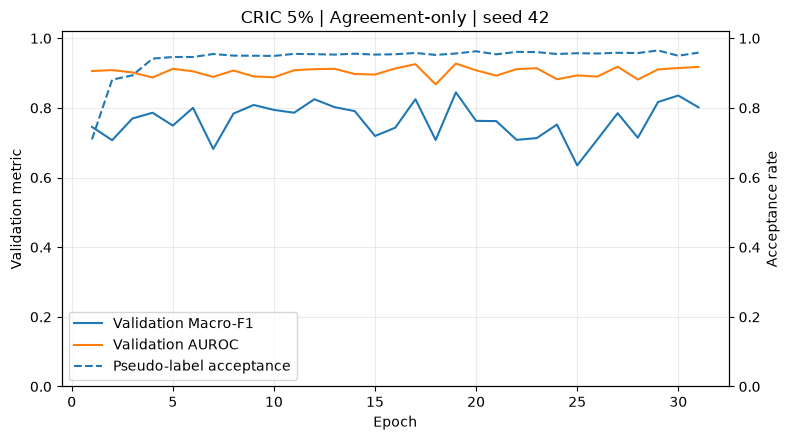

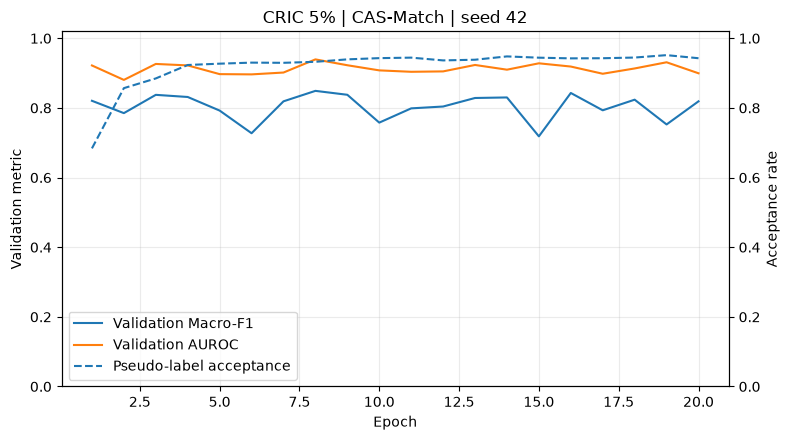

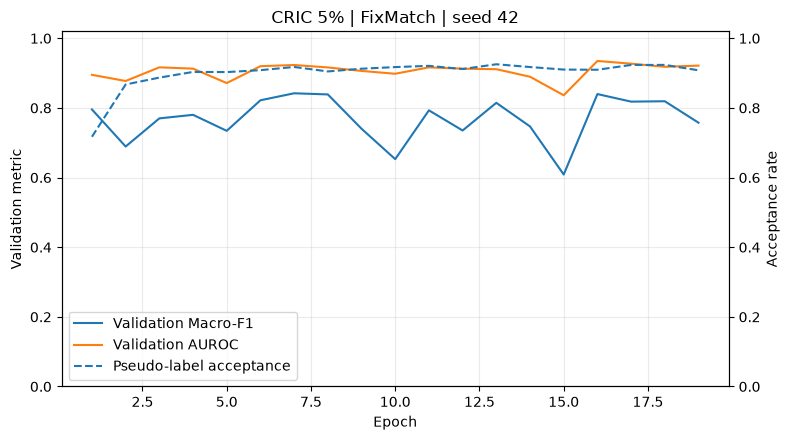

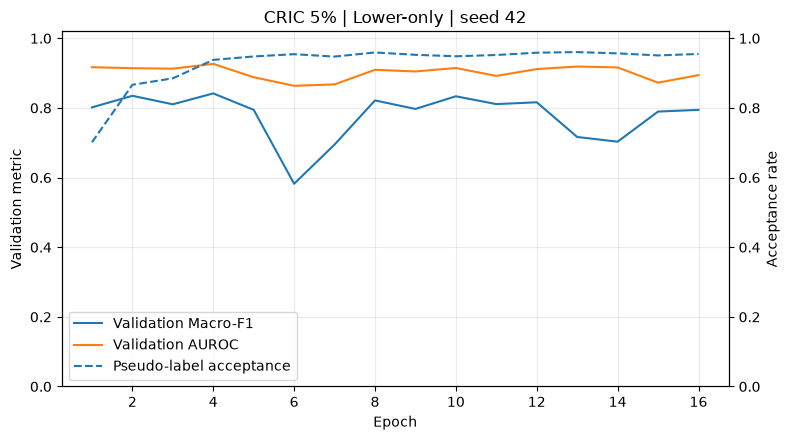

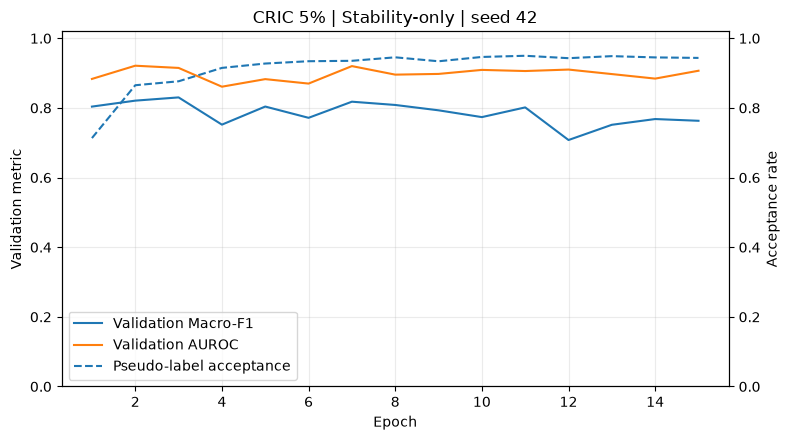

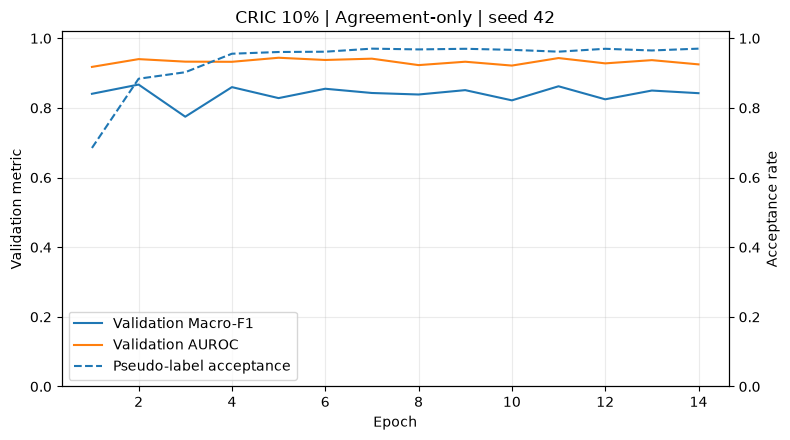

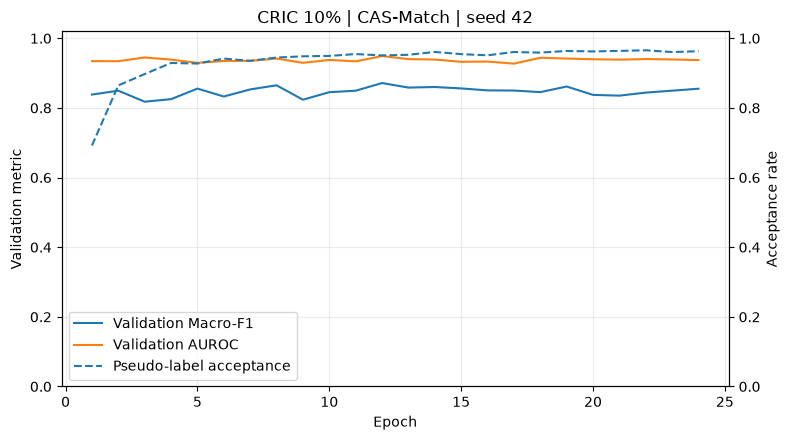

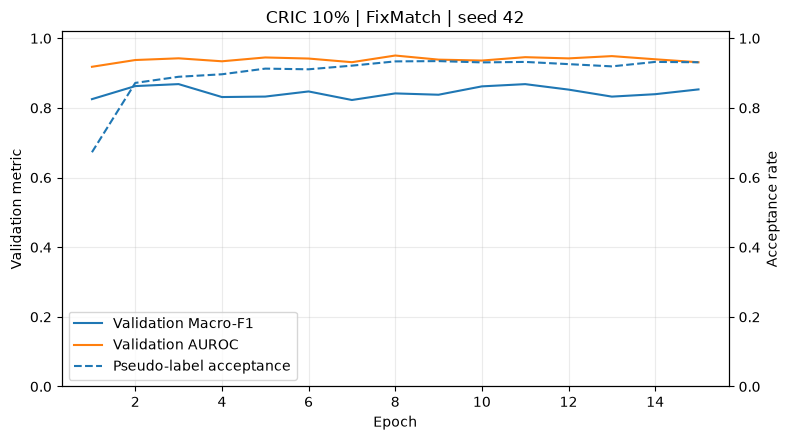

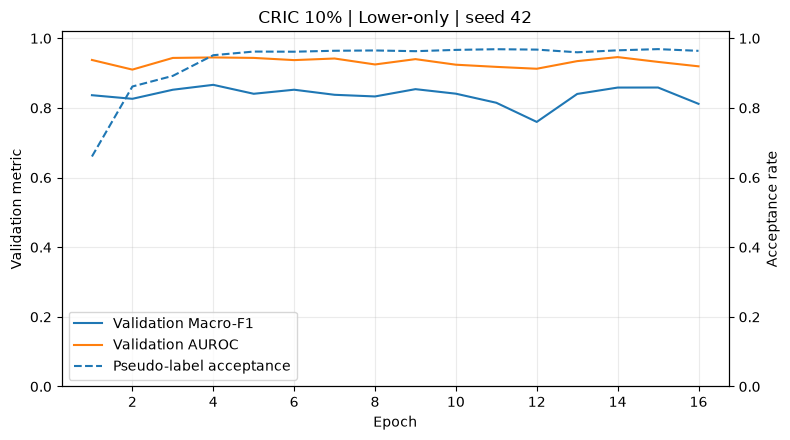

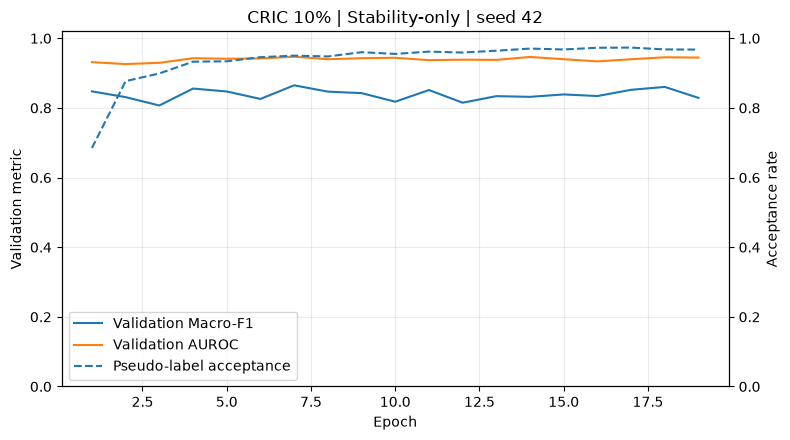

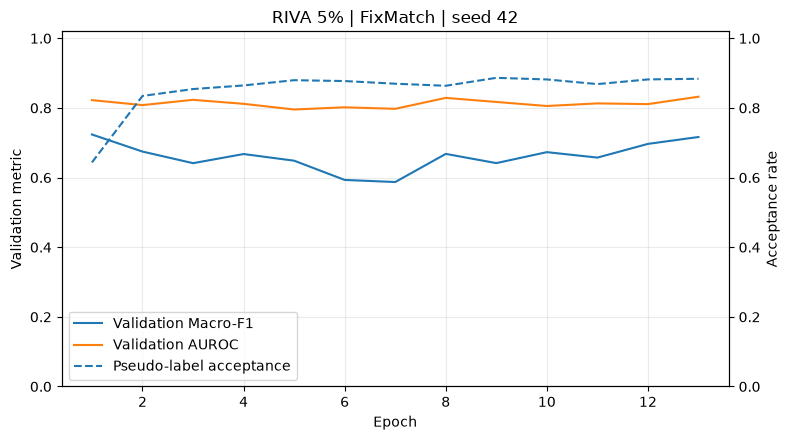

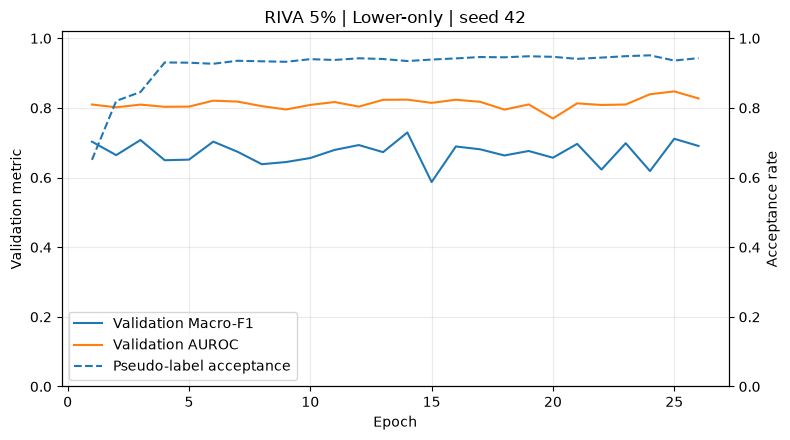

,method,dataset,label_percent,seed,epoch,train_loss,val_macro_f1,val_auroc,pseudo_acceptance_rate,accepted_normal,accepted_abnormal,tau_low_normal,tau_low_abnormal
0,Agreement-only,CRIC,5,42,1,0.114764,0.745642,0.905893,0.709648,3221,2222,0.95,0.95
1,Agreement-only,CRIC,5,42,2,0.035102,0.707330,0.908680,0.881226,3969,2790,0.95,0.95
2,Agreement-only,CRIC,5,42,3,0.042254,0.769636,0.902009,0.893481,4031,2822,0.95,0.95
3,Agreement-only,CRIC,5,42,4,0.052782,0.786210,0.887272,0.941591,4228,2994,0.80,0.80
4,Agreement-only,CRIC,5,42,5,0.042237,0.749300,0.912366,0.946284,4332,2926,0.80,0.80
5,Agreement-only,CRIC,5,42,6,0.052053,0.800392,0.905116,0.946284,4274,2984,0.80,0.80
6,Agreement-only,CRIC,5,42,7,0.046041,0.682173,0.889093,0.954889,4246,3078,0.80,0.80
7,Agreement-only,CRIC,5,42,8,0.048651,0.783776,0.907582,0.950196,4213,3075,0.80,0.80
8,Agreement-only,CRIC,5,42,9,0.046777,0.808544,0.890534,0.949935,4199,3087,0.80,0.80
9,Agreement-only,CRIC,5,42,10,0.043835,0.794302,0.888137,0.949413,4235,3047,0.80,0.80


,method,dataset,label_percent,seed,predicted_class,pool_n,accepted_n,acceptance_rate,accepted_correct_n,accepted_precision_posthoc,accepted_true_normal_n,accepted_true_abnormal_n,high_n,low_n
0,Agreement-only,CRIC,5,42,0,20,20,1.000000,19,0.950000,19,1,19,1
1,Agreement-only,CRIC,5,42,1,12,12,1.000000,11,0.916667,1,11,11,1
2,Agreement-only,CRIC,5,42,0,17,17,1.000000,17,1.000000,17,0,16,1
3,Agreement-only,CRIC,5,42,1,15,14,0.933333,13,0.928571,1,13,14,0
4,Agreement-only,CRIC,5,42,0,15,15,1.000000,14,0.933333,14,1,13,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6003,Lower-only,RIVA,5,42,1,6,6,1.000000,5,0.833333,1,5,6,0
6004,Lower-only,RIVA,5,42,0,19,18,0.947368,13,0.722222,13,5,16,2
6005,Lower-only,RIVA,5,42,1,13,12,0.923077,9,0.750000,3,9,10,2
6006,Lower-only,RIVA,5,42,0,16,14,0.875000,11,0.785714,11,3,12,2


In [10]:
history_frames = []
diagnostic_frames = []
for _, r in results.iterrows():
    run_dir = Path(r.run_dir)
    hp = run_dir / "history.csv"
    if hp.exists():
        h = pd.read_csv(hp)
        h.insert(0, "seed", int(r.seed))
        h.insert(0, "label_percent", int(r.label_percent))
        h.insert(0, "dataset", r.dataset.upper())
        h.insert(0, "method", r.method_label)
        history_frames.append(h)
        fig, ax1 = plt.subplots(figsize=(8, 4.5))
        ax1.plot(h.epoch, h.val_macro_f1, label="Validation Macro-F1")
        if "val_auroc" in h:
            ax1.plot(h.epoch, h.val_auroc, label="Validation AUROC")
        ax1.set_xlabel("Epoch")
        ax1.set_ylabel("Validation metric")
        ax1.set_ylim(0, 1.02)
        ax1.grid(alpha=0.25)
        ax2 = ax1.twinx()
        if "pseudo_acceptance_rate" in h:
            ax2.plot(h.epoch, h.pseudo_acceptance_rate, linestyle="--", label="Pseudo-label acceptance")
            ax2.set_ylabel("Acceptance rate")
            ax2.set_ylim(0, 1.02)
        ax1.set_title(f'{r.dataset.upper()} {int(r.label_percent)}% | {r.method_label} | seed {int(r.seed)}')
        lines, labels = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines+lines2, labels+labels2, loc="best")
        fig.tight_layout()
        safe_method = re.sub(r"[^a-z0-9]+", "_", r.method)
        out = REPORT_DIR / f"training_{r.dataset}_{int(r.label_percent)}pct_{safe_method}_seed{int(r.seed)}.png"
        fig.savefig(out, dpi=250, bbox_inches="tight")
        plt.show()
        plt.close(fig)

    dp = run_dir / "pseudo_label_epoch_diagnostics.csv"
    if dp.exists():
        try:
            d = pd.read_csv(dp)
            d.insert(0, "seed", int(r.seed))
            d.insert(0, "label_percent", int(r.label_percent))
            d.insert(0, "dataset", r.dataset.upper())
            d.insert(0, "method", r.method_label)
            diagnostic_frames.append(d)
        except Exception as exc:
            warnings.warn(f"Could not read {dp}: {exc}")

if history_frames:
    all_history = pd.concat(history_frames, ignore_index=True)
    all_history.to_csv(REPORT_DIR / "all_training_histories.csv", index=False)
    display(all_history.head(20))
else:
    all_history = pd.DataFrame()
    print("No history.csv files found.")

if diagnostic_frames:
    diagnostics = pd.concat(diagnostic_frames, ignore_index=True)
    display(diagnostics)
    diagnostics.to_csv(REPORT_DIR / "final_epoch_pseudo_label_diagnostics.csv", index=False)
else:
    diagnostics = pd.DataFrame()
    print("No pseudo-label diagnostic files found.")


## 11. CRIC-focused report tables

These tables are formatted for the main CAS-Match analysis. They remain separated from the Phase 11 supervised / pseudo-labelling / Mean Teacher benchmark results.


In [11]:
cric_runs = results[results.dataset == "cric"].copy()
cric_table = cric_runs.pivot_table(
    index=["label_percent", "method_label"],
    columns="seed",
    values=["macro_f1", "auroc", "abnormal_recall", "specificity_normal"],
    aggfunc="first"
).sort_index()
display(cric_table)
cric_table.to_csv(REPORT_DIR / "cric_seed_level_comparison.csv")

cric_aggregate = aggregate_table[aggregate_table.dataset == "cric"].copy()
display(cric_aggregate)
cric_aggregate.to_csv(REPORT_DIR / "cric_aggregate_results.csv", index=False)

riva_aggregate = aggregate_table[aggregate_table.dataset == "riva"].copy()
display(riva_aggregate if not riva_aggregate.empty else pd.DataFrame({"Note":["No RIVA results found."]}))
riva_aggregate.to_csv(REPORT_DIR / "riva_aggregate_results_available_only.csv", index=False)


abnormal_recall     auroc  macro_f1  \
seed                                      42        42        42   
label_percent method_label                                         
5             Agreement-only        0.794034  0.938728  0.848182   
              CAS-Match             0.730114  0.941513  0.846915   
              FixMatch              0.754261  0.942340  0.848300   
              Lower-only            0.850852  0.928174  0.839857   
              Stability-only        0.832386  0.919568  0.827557   
10            Agreement-only        0.758523  0.941882  0.851439   
              CAS-Match             0.845170  0.950800  0.859336   
              FixMatch              0.794034  0.947860  0.853600   
              Lower-only            0.855114  0.947803  0.861379   
              Stability-only        0.838068  0.951133  0.873787   

                             specificity_normal  
seed                                         42  
label_percent method_label                       
5             Agreement-only           0.904554  
              CAS-Match                0.938865  
              FixMatch                 0.927012  
              Lower-only               0.861510  
              Stability-only           0.854024  
10            Agreement-only           0.928883  
              CAS-Match                0.892077  
              FixMatch                 0.912040  
              Lower-only               0.889582  
              Stability-only           0.915783

,dataset,label_percent,method,method_label,macro_f1_mean,macro_f1_std,macro_f1_count,auroc_mean,auroc_std,auroc_count,...,precision_abnormal_count,specificity_normal_mean,specificity_normal_std,specificity_normal_count,normal_f1_mean,normal_f1_std,normal_f1_count,abnormal_f1_mean,abnormal_f1_std,abnormal_f1_count
0,cric,5,agreement_only,Agreement-only,0.848182,NaN,1,0.938728,NaN,1,...,1,0.904554,NaN,1,0.906817,NaN,1,0.789548,NaN,1
1,cric,5,cas_match,CAS-Match,0.846915,NaN,1,0.941513,NaN,1,...,1,0.938865,NaN,1,0.912674,NaN,1,0.781155,NaN,1
2,cric,5,fixmatch,FixMatch,0.848300,NaN,1,0.942340,NaN,1,...,1,0.927012,NaN,1,0.911097,NaN,1,0.785503,NaN,1
3,cric,5,lower_only,Lower-only,0.839857,NaN,1,0.928174,NaN,1,...,1,0.861510,NaN,1,0.894140,NaN,1,0.785574,NaN,1
4,cric,5,stability_only,Stability-only,0.827557,NaN,1,0.919568,NaN,1,...,1,0.854024,NaN,1,0.886084,NaN,1,0.769029,NaN,1
5,cric,10,agreement_only,Agreement-only,0.851439,NaN,1,0.941882,NaN,1,...,1,0.928883,NaN,1,0.912937,NaN,1,0.789941,NaN,1
6,cric,10,cas_match,CAS-Match,0.859336,NaN,1,0.950800,NaN,1,...,1,0.892077,NaN,1,0.910248,NaN,1,0.808424,NaN,1
7,cric,10,fixmatch,FixMatch,0.853600,NaN,1,0.947860,NaN,1,...,1,0.912040,NaN,1,0.910903,NaN,1,0.796296,NaN,1
8,cric,10,lower_only,Lower-only,0.861379,NaN,1,0.947803,NaN,1,...,1,0.889582,NaN,1,0.910891,NaN,1,0.811868,NaN,1
9,cric,10,stability_only,Stability-only,0.873787,NaN,1,0.951133,NaN,1,...,1,0.915783,NaN,1,0.921821,NaN,1,0.825752,NaN,1


,dataset,label_percent,method,method_label,macro_f1_mean,macro_f1_std,macro_f1_count,auroc_mean,auroc_std,auroc_count,...,precision_abnormal_count,specificity_normal_mean,specificity_normal_std,specificity_normal_count,normal_f1_mean,normal_f1_std,normal_f1_count,abnormal_f1_mean,abnormal_f1_std,abnormal_f1_count
10,riva,5,fixmatch,FixMatch,0.785452,NaN,1,0.872355,NaN,1,...,1,0.828502,NaN,1,0.843788,NaN,1,0.727116,NaN,1
11,riva,5,lower_only,Lower-only,0.777659,NaN,1,0.861512,NaN,1,...,1,0.831884,NaN,1,0.840410,NaN,1,0.714908,NaN,1


## 12. Export inventory

All outputs are written to `data/results/cas_match_v1/report_results/`. The notebook does not overwrite original experiment metrics, histories, checkpoints or calibration files.


In [12]:
files = sorted(p for p in REPORT_DIR.iterdir() if p.is_file())
inventory = pd.DataFrame({
    "file": [p.name for p in files],
    "size_kb": [round(p.stat().st_size / 1024, 1) for p in files]
})
display(inventory)
print(f"\nDone. {len(files)} report asset(s) are in: {REPORT_DIR}")


,file,size_kb
0,all_completed_run_metrics.csv,5.0
1,all_training_histories.csv,26.8
2,cm_cric_10pct_agreement_only_seed42.png,64.7
3,cm_cric_10pct_cas_match_seed42.png,64.1
4,cm_cric_10pct_fixmatch_seed42.png,61.7
5,cm_cric_10pct_lower_only_seed42.png,64.4
6,cm_cric_10pct_stability_only_seed42.png,64.9
7,cm_cric_5pct_agreement_only_seed42.png,64.2
8,cm_cric_5pct_cas_match_seed42.png,63.3
9,cm_cric_5pct_fixmatch_seed42.png,61.7



Done. 45 report asset(s) are in: C:\Users\nanda\Documents\cervical-semi-sl\data\results\cas_match_v1\report_results
